In [1]:
import os
import kagglehub
from google.colab import drive

#drive.mount('/content/drive')

download_path = kagglehub.dataset_download("divg07/casia-20-image-tampering-detection-dataset")

if not os.path.exists('/content/dataset'):
    os.symlink(download_path, '/content/dataset')

Using Colab cache for faster access to the 'casia-20-image-tampering-detection-dataset' dataset.


In [2]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageChops, ImageEnhance
import glob


In [3]:
DRIVE_PROJECT_PATH = "/content/drive/MyDrive/IPCV_Forgery_Detection"
os.makedirs(DRIVE_PROJECT_PATH, exist_ok=True)


LOCAL_DATASET_PATH = "/content/dataset/CASIA2"
AUTH_PATH = os.path.join(LOCAL_DATASET_PATH, "Au")
TAMP_PATH = os.path.join(LOCAL_DATASET_PATH, "Tp")

print("Authentic images:", len(os.listdir(AUTH_PATH)))
print("Tampered images:", len(os.listdir(TAMP_PATH)))
print("Outputs will be saved to:", DRIVE_PROJECT_PATH)

Authentic images: 7492
Tampered images: 5125
Outputs will be saved to: /content/drive/MyDrive/IPCV_Forgery_Detection


In [4]:
IMG_WIDTH = 128
IMG_HEIGHT = 128
IMG_CHANNELS = 3
IMAGE_SIZE = (IMG_WIDTH, IMG_HEIGHT)
BATCH_SIZE = 32
EPOCHS = 50

In [5]:
# Cell 3: Define Error Level Analysis (ELA) Function
# ELA highlights differences in compression levels.
# Forged regions, when re-saved, will have a different compression artifact signature.

def convert_to_ela_image(image_path, quality=90):
    """
    Generates an ELA image from a given image path.
    Saves the image at a 'quality' level, then finds the difference
    between the original and the re-compressed image.
    """
    try:
        original_image = Image.open(image_path).convert('RGB')
        original_image.save("temp_resaved.jpg", "JPEG", quality=quality)

        resaved_image = Image.open("temp_resaved.jpg")

        # Find difference
        ela_image = ImageChops.difference(original_image, resaved_image)

        # Enhance the difference to make it more visible
        extrema = ela_image.getextrema()
        max_diff = max([ex[1] for ex in extrema])
        if max_diff == 0:
            max_diff = 1 # Avoid division by zero

        scale = 255.0 / max_diff
        ela_image = ImageEnhance.Brightness(ela_image).enhance(scale)

        # Clean up temp file
        os.remove("temp_resaved.jpg")

        return ela_image.resize(IMAGE_SIZE)

    except Exception as e:
        print(f"Error processing {image_path}: {e}")
        return None

In [6]:
# Cell 4: Load and Preprocess Data
# We will load all authentic images (Label 0) and tampered images (Label 1)
# and convert them to ELA images.

X = [] # ELA Images
y = [] # Labels (0 = Authentic, 1 = Tampered)
original_paths = [] # Store original file paths

print("Loading authentic images...")
# Note: glob.glob is used to find all image files. Adjust "*.jpg" if you have .png, .bmp etc.
authentic_images = glob.glob(os.path.join(AUTH_PATH, "**", "*.jpg"), recursive=True) + \
                   glob.glob(os.path.join(AUTH_PATH, "**", "*.png"), recursive=True)

if not authentic_images:
    print("Warning: No authentic images found. Check your AUTH_PATH.")

for path in authentic_images:
    ela_img = convert_to_ela_image(path)
    if ela_img:
        X.append(img_to_array(ela_img))
        y.append(0)
        original_paths.append(path)

print(f"Loaded {len(y)} authentic images.")

print("Loading tampered images...")
tampered_images = glob.glob(os.path.join(TAMP_PATH, "**", "*.jpg"), recursive=True) + \
                  glob.glob(os.path.join(TAMP_PATH, "**", "*.png"), recursive=True) + \
                  glob.glob(os.path.join(TAMP_PATH, "**", "*.bmp"), recursive=True)

if not tampered_images:
    print("Warning: No tampered images found. Check your TAMP_PATH.")

tampered_count = 0
for path in tampered_images:
    # CASIA often has ground truth masks ending in '_gt'. We want to skip these.
    if not path.endswith('_gt.png') and not path.endswith('_gt.bmp'):
        ela_img = convert_to_ela_image(path)
        if ela_img:
            X.append(img_to_array(ela_img))
            y.append(1)
            original_paths.append(path)
            tampered_count += 1

print(f"Loaded {tampered_count} tampered images.")

# Convert to numpy arrays
X = np.array(X)
y = np.array(y)
original_paths = np.array(original_paths)

print(f"Total dataset size: X shape: {X.shape}, y shape: {y.shape}, paths shape: {original_paths.shape}")

# Normalize data (ELA images are already 0-255, so just scale)
X = X / 255.0

# Split the dataset - ensure paths are split consistently
X_train, X_temp, y_train, y_temp, paths_train, paths_temp = train_test_split(
    X, y, original_paths, test_size=0.2, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test, paths_val, paths_test = train_test_split(
    X_temp, y_temp, paths_temp, test_size=0.5, random_state=42, stratify=y_temp
)

print(f"Train set: {X_train.shape}, Validation set: {X_val.shape}, Test set: {X_test.shape}")
print(f"Validation paths set: {paths_val.shape}")

Loading authentic images...
Loaded 7437 authentic images.
Loading tampered images...
Loaded 2064 tampered images.
Total dataset size: X shape: (9501, 128, 128, 3), y shape: (9501,), paths shape: (9501,)
Train set: (7600, 128, 128, 3), Validation set: (950, 128, 128, 3), Test set: (951, 128, 128, 3)
Validation paths set: (950,)


In [7]:
# Cell 5: Build the Lightweight CNN Model
# This is a simple, lightweight model.
# 3 Conv/Pool blocks, followed by 2 Dense layers.
# BatchNormalization and Dropout are used to prevent overfitting.

def build_lightweight_cnn(input_shape):
    model = Sequential()

    # Input Layer
    model.add(Conv2D(32, (3, 3), activation='relu', input_shape=input_shape, padding='same'))
    model.add(BatchNormalization())
    model.add(MaxPooling2D((2, 2)))

    # Block 2
    model.add(Conv2D(64, (3, 3), activation='relu', padding='same'))
    model.add(BatchNormalization())
    model.add(MaxPooling2D((2, 2)))

    # Block 3
    model.add(Conv2D(128, (3, 3), activation='relu', padding='same'))
    model.add(BatchNormalization())
    model.add(MaxPooling2D((2, 2)))

    # Flatten and Dense Layers
    model.add(Flatten())
    model.add(Dense(128, activation='relu'))
    model.add(Dropout(0.5))

    # Output Layer (Binary Classification)
    model.add(Dense(1, activation='sigmoid'))

    return model

model = build_lightweight_cnn((IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS))
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,705 (16.36 MB)

 Trainable params: 4,288,257 (16.36 MB)

 Non-trainable params: 448 (1.75 KB)

In [8]:
# Cell 6: Compile and Train the Model

# Compile
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
              loss='binary_crossentropy',
              metrics=['accuracy'])

# Callbacks
# Save the best model
checkpoint = ModelCheckpoint('best_model.h5', save_best_only=True, monitor='val_accuracy', mode='max')
# Stop training if validation loss doesn't improve
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Train
history = model.fit(
    X_train,
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val),
    callbacks=[checkpoint, early_stop]
)

Epoch 1/50
238/238 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.8281 - loss: 0.4900

238/238 ━━━━━━━━━━━━━━━━━━━━ 33s 86ms/step - accuracy: 0.8563 - loss: 0.3500 - val_accuracy: 0.7832 - val_loss: 0.6459
Epoch 2/50
238/238 ━━━━━━━━━━━━━━━━━━━━ 16s 25ms/step - accuracy: 0.9082 - loss: 0.2177 - val_accuracy: 0.7832 - val_loss: 1.3674
Epoch 3/50
238/238 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9302 - loss: 0.1691

238/238 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - accuracy: 0.9303 - loss: 0.1695 - val_accuracy: 0.8979 - val_loss: 0.2335
Epoch 4/50
237/238 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9401 - loss: 0.1358

238/238 ━━━━━━━━━━━━━━━━━━━━ 7s 30ms/step - accuracy: 0.9414 - loss: 0.1337 - val_accuracy: 0.9316 - val_loss: 0.1692
Epoch 5/50
238/238 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9435 - loss: 0.1286

238/238 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.9501 - loss: 0.1172 - val_accuracy: 0.9347 - val_loss: 0.1381
Epoch 6/50
237/238 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9682 - loss: 0.0881

238/238 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.9636 - loss: 0.0933 - val_accuracy: 0.9400 - val_loss: 0.1342
Epoch 7/50
238/238 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9675 - loss: 0.0798

238/238 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.9676 - loss: 0.0784 - val_accuracy: 0.9411 - val_loss: 0.1538
Epoch 8/50
238/238 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - accuracy: 0.9761 - loss: 0.0625 - val_accuracy: 0.9411 - val_loss: 0.1415
Epoch 9/50
238/238 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.9780 - loss: 0.0609 - val_accuracy: 0.9337 - val_loss: 0.1854
Epoch 10/50
236/238 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9815 - loss: 0.0558

238/238 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.9800 - loss: 0.0575 - val_accuracy: 0.9589 - val_loss: 0.1358
Epoch 11/50
238/238 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.9838 - loss: 0.0440 - val_accuracy: 0.9368 - val_loss: 0.1874
Epoch 12/50
238/238 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.9863 - loss: 0.0372 - val_accuracy: 0.9368 - val_loss: 0.2139
Epoch 13/50
238/238 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - accuracy: 0.9874 - loss: 0.0345 - val_accuracy: 0.9558 - val_loss: 0.1581
Epoch 14/50
238/238 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.9899 - loss: 0.0307 - val_accuracy: 0.9505 - val_loss: 0.1761
Epoch 15/50
238/238 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - accuracy: 0.9884 - loss: 0.0329 - val_accuracy: 0.8905 - val_loss: 0.7197
Epoch 16/50
238/238 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.9905 - loss: 0.0291 - val_accuracy: 0.9305 - val_loss: 0.2815


30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 123ms/step
--- Model Evaluation (Test Set) ---
Test Accuracy: 94.95%
Test Precision: 87.32%
Test Recall: 89.86%
Test ROC-AUC: 98.62%

Classification Report (Test Set):

              precision    recall  f1-score   support

   Authentic       0.97      0.96      0.97       744
    Tampered       0.87      0.90      0.89       207

    accuracy                           0.95       951
   macro avg       0.92      0.93      0.93       951
weighted avg       0.95      0.95      0.95       951



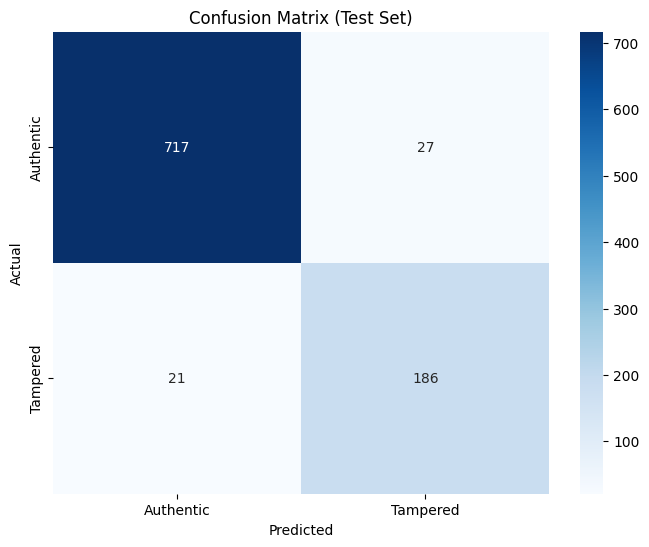

In [9]:
# Cell 7: Evaluate Model Performance (Metrics) - Using Test Set

# Load the best weights saved during training
model.load_weights('best_model.h5')

# Make predictions on test data
y_pred_proba = model.predict(X_test)
y_pred = (y_pred_proba > 0.5).astype(int)

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print(f"--- Model Evaluation (Test Set) ---")
print(f"Test Accuracy: {accuracy * 100:.2f}%")
print(f"Test Precision: {precision * 100:.2f}%")
print(f"Test Recall: {recall * 100:.2f}%")
print(f"Test ROC-AUC: {roc_auc * 100:.2f}%")
print("\nClassification Report (Test Set):\n")
print(classification_report(y_test, y_pred, target_names=['Authentic', 'Tampered']))

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Authentic', 'Tampered'],
            yticklabels=['Authentic', 'Tampered'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (Test Set)')
plt.show()

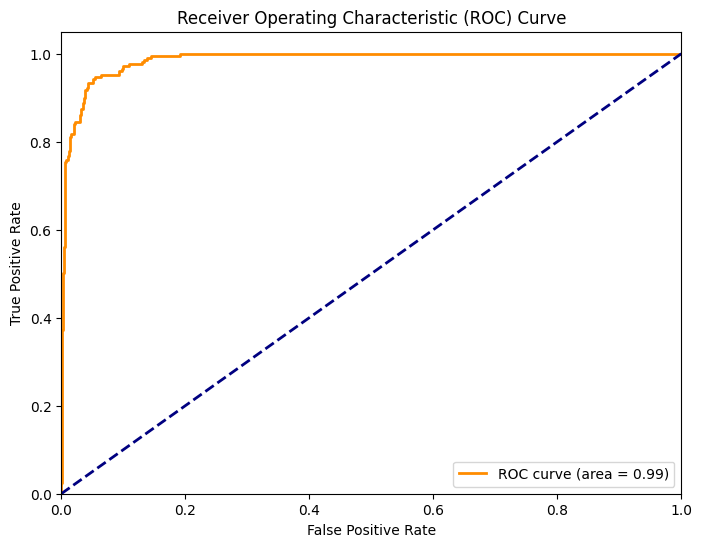

In [10]:
from sklearn.metrics import roc_curve

# Plot ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = roc_auc_score(y_test, y_pred_proba)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

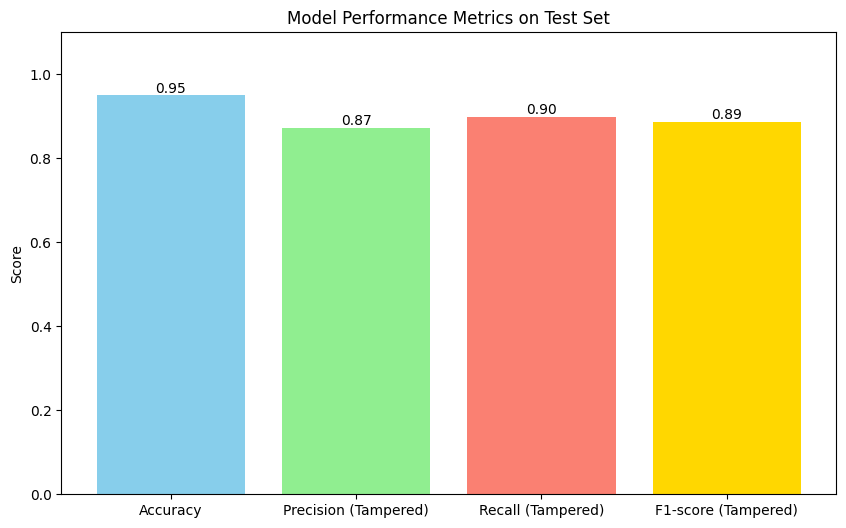

In [11]:
# Visualize Performance Metrics (Accuracy, Precision, Recall, F1-score)
from sklearn.metrics import f1_score

# Assuming y_test and y_pred are available from previous cells (e.g., cell bTze5LNSV9MQ)
# If not, you would need to re-calculate predictions:
# y_pred_proba = model.predict(X_test)
# y_pred = (y_pred_proba > 0.5).astype(int)

# Calculate F1-score for the positive class (Tampered, label 1)
f1 = f1_score(y_test, y_pred)

metrics_names = ['Accuracy', 'Precision (Tampered)', 'Recall (Tampered)', 'F1-score (Tampered)']
metrics_values = [accuracy, precision, recall, f1]

plt.figure(figsize=(10, 6))
bars = plt.bar(metrics_names, metrics_values, color=['skyblue', 'lightgreen', 'salmon', 'gold'])
plt.ylim(0, 1.1) # Increase y-limit slightly to fit text
plt.ylabel('Score')
plt.title('Model Performance Metrics on Test Set')

# Add the value on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval, f'{yval:.2f}', va='bottom', ha='center') # va: vertical alignment, ha: horizontal alignment

plt.show()

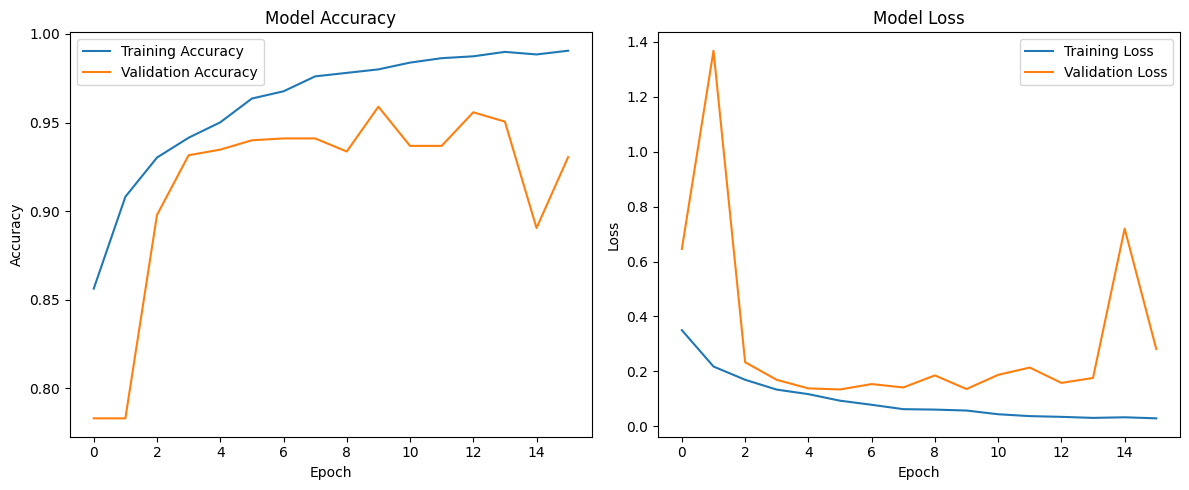

In [12]:

# Cell 8: Plot Training History

plt.figure(figsize=(12, 5))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Error loading original image /content/dataset/CASIA2/Au/Au_art_30680.jpg: name 'cv2' is not defined
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
Error loading original image /content/dataset/CASIA2/Au/Au_pla_30106.jpg: name 'cv2' is not defined
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
Error loading original image /content/dataset/CASIA2/Au/Au_pla_30448.jpg: name 'cv2' is not defined
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
Error loading original image /content/dataset/CASIA2/Tp/Tp_S_NRN_S_N_ind00085_ind00085_10674.jpg: name 'cv2' is not defined
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
Error loading original image /content/dataset/CASIA2/Au/Au_arc_30497.jpg: name 'cv2' is not defined


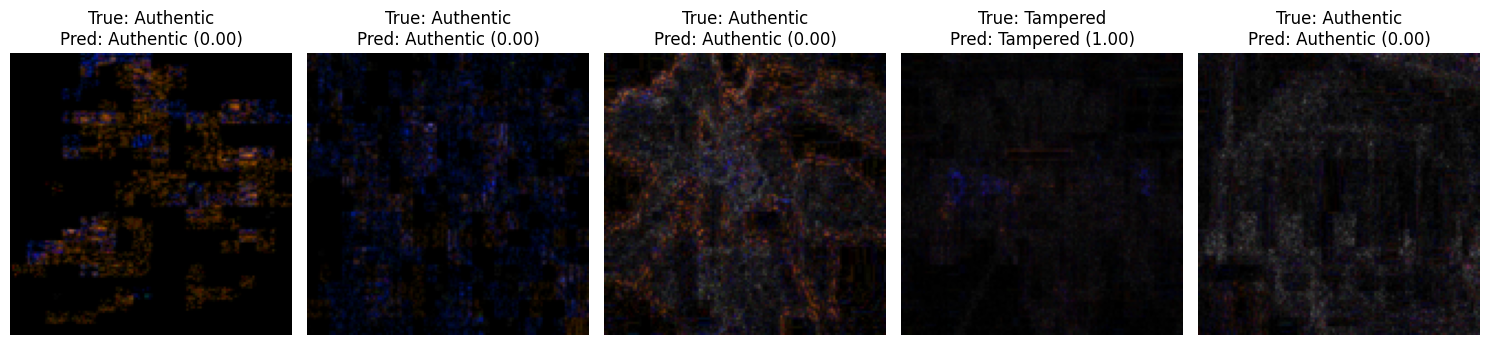

In [13]:
# Sample Predictions from the Model

# Select a few sample indices from the test set
sample_indices = np.random.choice(len(X_test), 5, replace=False) # Choose 5 random samples

plt.figure(figsize=(15, 10))

for i, idx in enumerate(sample_indices):
    img_array = X_test[idx]
    true_label = y_test[idx]
    original_path = paths_test[idx] # Use paths_test to get original path

    # Make prediction
    img_array_expanded = np.expand_dims(img_array, axis=0)
    prediction_proba = model.predict(img_array_expanded)[0][0]
    predicted_label = 1 if prediction_proba > 0.5 else 0

    true_label_str = "Tampered" if true_label == 1 else "Authentic"
    predicted_label_str = "Tampered" if predicted_label == 1 else "Authentic"

    # Load original image for display (since ELA is input, show original)
    try:
        original_img = cv2.imread(original_path)
        original_img = cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB)
        original_img = cv2.resize(original_img, (IMG_WIDTH, IMG_HEIGHT)) # Resize to match ELA size for consistent display
    except Exception as e:
        print(f"Error loading original image {original_path}: {e}")
        original_img = (img_array * 255).astype(np.uint8) # Fallback to ELA if original fails


    plt.subplot(2, 5, i + 1)
    plt.imshow(original_img)
    plt.title(f"True: {true_label_str}\nPred: {predicted_label_str} ({prediction_proba:.2f})")
    plt.axis('off')

    # Display ELA image as well (optional, but good to see model input)
    # plt.subplot(2, 5, i + 6) # Uncomment if you want to show ELA below original
    # plt.imshow((img_array * 255).astype(np.uint8))
    # plt.title("ELA Input")
    # plt.axis('off')

plt.tight_layout()
plt.show()

In [14]:
model.save('forgery_detection_model.keras')
print("Model saved as forgery_detection_model.keras")

Model saved as forgery_detection_model.keras


Authentic ELA Image FFT:


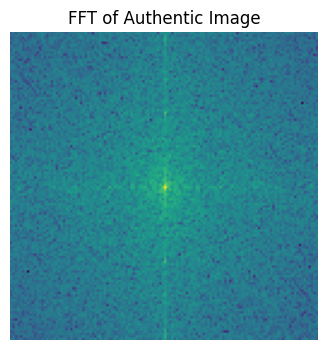

Tampered ELA Image FFT:


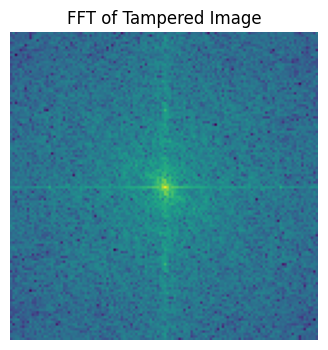

In [15]:
# Cell 9: Visualize Frequency Spectrum (FFT) -- compare Authentic vs. Tampered

def plot_fft_of_image(image_array, title="FFT Spectrum"):
    """
    Plots the magnitude spectrum of an image's grayscale FFT.
    """
    from numpy.fft import fft2, fftshift
    gray = np.mean(image_array, axis=2)  # ELA is color, but spectrum often analyzed in gray
    f = fft2(gray)
    fshift = fftshift(f)
    magnitude_spectrum = 20 * np.log(np.abs(fshift) + 1e-8)
    plt.figure(figsize=(5,4))
    plt.imshow(magnitude_spectrum, cmap='viridis')
    plt.title(title)
    plt.axis('off')
    plt.show()

# Show FFT spectra for some samples
idx_auth = np.where(y_test==0)[0][0] # First authentic sample in test set
idx_tamp = np.where(y_test==1)[0][0] # First tampered sample

print("Authentic ELA Image FFT:")
plot_fft_of_image(X_test[idx_auth], "FFT of Authentic Image")
print("Tampered ELA Image FFT:")
plot_fft_of_image(X_test[idx_tamp], "FFT of Tampered Image")

Using last convolutional layer: conv2d_2
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
Ground Truth: Authentic, Predicted: Authentic (0.00)
Path: /content/dataset/CASIA2/Au/Au_nat_30392.jpg


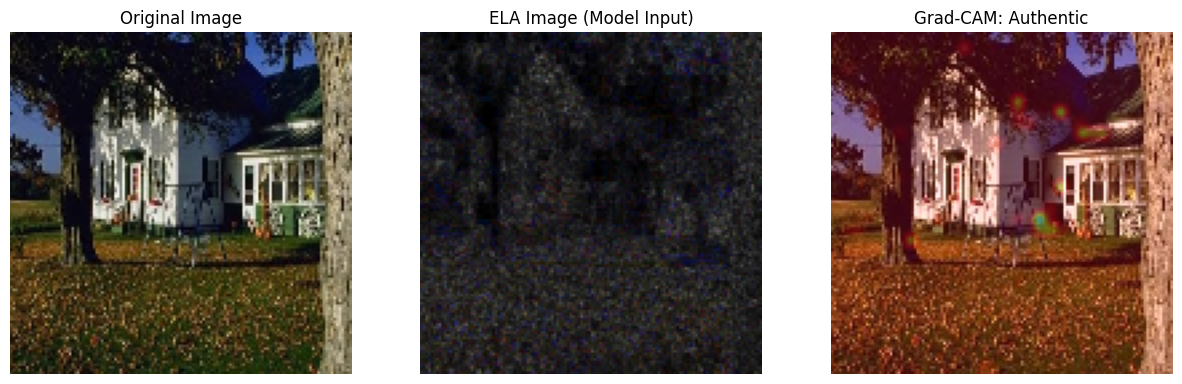

In [17]:
# Cell 10: Grad-CAM Visualization for Model Explainability

# Helper function to dynamically find the last convolutional layer
import cv2
def get_last_conv_layer(model):
    for layer in reversed(model.layers):
        if isinstance(layer, tf.keras.layers.Conv2D):
            return layer.name
    raise ValueError("No Conv2D layer found in model.")

# Function to generate the Grad-CAM heatmap (Revised for robustness)
def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    # Prepare the image tensor
    img_tensor = tf.convert_to_tensor(img_array, dtype=tf.float32)

    # First, we create a model that maps the input image to the activations
    # of the last convolutional layer
    grad_model_part1 = tf.keras.models.Model(
        model.inputs, model.get_layer(last_conv_layer_name).output
    )

    # Then, we create a model that maps the activations of the last conv layer
    # to the final class predictions
    classifier_input = tf.keras.Input(shape=grad_model_part1.output.shape[1:])
    x = classifier_input
    # Iterate through layers starting from the one *after* the last conv layer
    for layer in model.layers[model.layers.index(model.get_layer(last_conv_layer_name)) + 1:]:
        x = layer(x)
    grad_model_part2 = tf.keras.models.Model(classifier_input, x)

    with tf.GradientTape() as tape:
       # Watch the output of the first part (activations of the last conv layer)
        # This is what we want to take gradients with respect to.
        last_conv_layer_output = grad_model_part1(img_tensor)
        tape.watch(last_conv_layer_output)

        # Pass the activations through the rest of the model (classifier part)
        preds = grad_model_part2(last_conv_layer_output)

        # If pred_index is not provided, use the highest probability class
        if pred_index is None:
            # For binary classification (sigmoid output), pred_index is usually 0
            # because there's only one output neuron representing the probability of the positive class.
            # tf.argmax on a (batch_size, 1) tensor will yield 0.
            pred_index = 0

        class_channel = preds[:, pred_index]

    # Compute the gradient of the predicted class with respect to the output of the last conv layer
    grads = tape.gradient(class_channel, last_conv_layer_output)

    # Check if gradients are None (indicating a problem in gradient computation)
    if grads is None:
        print(f"Warning: Gradients are None. Cannot compute heatmap.")
        # Return a heatmap of NaNs to indicate failure
        return np.full(last_conv_layer_output.shape[1:3], np.nan)

    # Pool the gradients across all the filters
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Multiply each channel in the last_conv_layer_output by its importance
    last_conv_layer_output = last_conv_layer_output[0] # Remove batch dimension
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # Normalize the heatmap to get a range between 0 and 1
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()
    # Function to display the original image, ELA input, and Grad-CAM overlay
def display_gradcam(original_img_path, ela_img_array, model, last_conv_layer_name, prediction_label):
    try:
        original_img = cv2.imread(original_img_path)
        original_img = cv2.resize(original_img, (IMG_WIDTH, IMG_HEIGHT))
        original_img = cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB)
    except Exception as e:
        print(f"Error loading original image {original_img_path}: {e}")
        # Fallback to displaying ELA if original image cannot be loaded
        original_img = (ela_img_array * 255).astype(np.uint8)

    heatmap = make_gradcam_heatmap(np.expand_dims(ela_img_array, axis=0), model, last_conv_layer_name)

    if np.isnan(heatmap).any():
        print("Heatmap generation failed (resulted in NaN). Skipping overlay.")
        return

    heatmap = cv2.resize(heatmap, (original_img.shape[1], original_img.shape[0]))
    heatmap = np.uint8(255 * heatmap)
    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

    superimposed_img = heatmap * 0.4 + original_img
    superimposed_img = np.clip(superimposed_img, 0, 255).astype(np.uint8)

    ela_plot_img = (ela_img_array * 255).astype(np.uint8)

    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1)
    plt.imshow(original_img)
    plt.title("Original Image")
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(ela_plot_img)
    plt.title("ELA Image (Model Input)")
    plt.axis('off')
    plt.subplot(1, 3, 3)
    plt.imshow(superimposed_img)
    plt.title(f"Grad-CAM: {prediction_label}")
    plt.axis('off')

    plt.show()


# Get the last convolutional layer name dynamically
LAST_CONV_LAYER_NAME = get_last_conv_layer(model)
print(f"Using last convolutional layer: {LAST_CONV_LAYER_NAME}")

# Select an authentic sample from the test set
authentic_indices = np.where(y_test == 0)[0]
if len(authentic_indices) > 0:
    sample_idx = authentic_indices[np.random.choice(len(authentic_indices))] # Get a random authentic index

    img_array_for_gradcam = X_test[sample_idx]
    original_path_for_gradcam = paths_test[sample_idx]
    true_label_for_gradcam = y_test[sample_idx]

    # Make a prediction for the selected image
    prediction_proba = model.predict(np.expand_dims(img_array_for_gradcam, axis=0))[0][0]
    predicted_label_str = "Tampered" if prediction_proba > 0.5 else "Authentic"
    true_label_str = "Tampered" if true_label_for_gradcam == 1 else "Authentic"

    print(f"Ground Truth: {true_label_str}, Predicted: {predicted_label_str} ({prediction_proba:.2f})\nPath: {original_path_for_gradcam}")
    display_gradcam(original_path_for_gradcam, img_array_for_gradcam, model, LAST_CONV_LAYER_NAME, predicted_label_str)
else:
    print("No authentic images found in the test set to display Grad-CAM for.")